# 06. Expresión diferencial con DESeq2

DESeq2 corrige diferencias en el total de conteos entre muestras, estima la variabilidad de cada gen con un modelo para conteos (binomial negativa) y prueba con la prueba de Wald si el cambio de expresión es distinto de cero. Su `padj` es el valor q de Benjamini-Hochberg.

In [1]:
suppressPackageStartupMessages({
    library(DESeq2)
    library(tidyverse)
})

dir_proc <- "../data/processed"
dir_tablas <- "../results/tablas"
dir_figuras <- "../results/figuras"

conteos <- read.csv(file.path(dir_proc, "pseudobulk_T_conteos.csv"),
                    row.names = 1, check.names = FALSE)
meta <- read.csv(file.path(dir_proc, "pseudobulk_T_meta.csv"), row.names = 1)

stopifnot(identical(colnames(conteos), rownames(meta)))
meta$condicion <- factor(meta$condicion, levels = c("Sano", "NL", "LS"))
meta


,condicion,donante,n_T
,<fct>,<chr>,<int>
465,Sano,465,29
486_LS,LS,486,35
632,Sano,632,33
BIO023_LS,LS,BIO023,23
CON161,Sano,CON161,27
CON171,Sano,CON171,71
CON194,Sano,CON194,32
DER114_LS,LS,DER114,298
DER114_NL,NL,DER114,101


El sexo se deduce de la suma de conteos de genes del cromosoma Y, porque GEO no lo reporta.

In [2]:
genes_y <- c("RPS4Y1", "DDX3Y", "UTY", "KDM5D", "USP9Y", "EIF1AY")
meta$sexo <- factor(ifelse(colSums(conteos[genes_y, ]) > 20, "M", "F"))
table(meta$condicion, meta$sexo)

      
       F M
  Sano 2 3
  NL   3 1
  LS   4 1

Se quitan genes técnicos (mitocondriales, el pseudogén MTRNR2L, ribosomales y segmentos V y J del receptor) y se evalúan los genes con al menos 10 conteos en al menos 4 muestras.

In [3]:
tecnicos <- grepl("^(MT-|MTRNR2L|RP[SL]|TR[ABDG][VJ]|IG[HKL][VJ])", rownames(conteos))
conteos <- conteos[!tecnicos, ]

dds <- DESeqDataSetFromMatrix(as.matrix(conteos), colData = meta, design = ~ condicion)
keep <- rowSums(counts(dds) >= 10) >= 4
dds <- dds[keep, ]
dds

class: DESeqDataSet 
dim: 3521 14 
metadata(1): version
assays(1): counts
rownames(3521): ISG15 TNFRSF18 ... IL9R USP9Y
rowData names(0):
colnames(14): 465 486_LS ... DER119_NL DER120_NL
colData names(4): condicion donante n_T sexo

using ntop=500 top features by variance



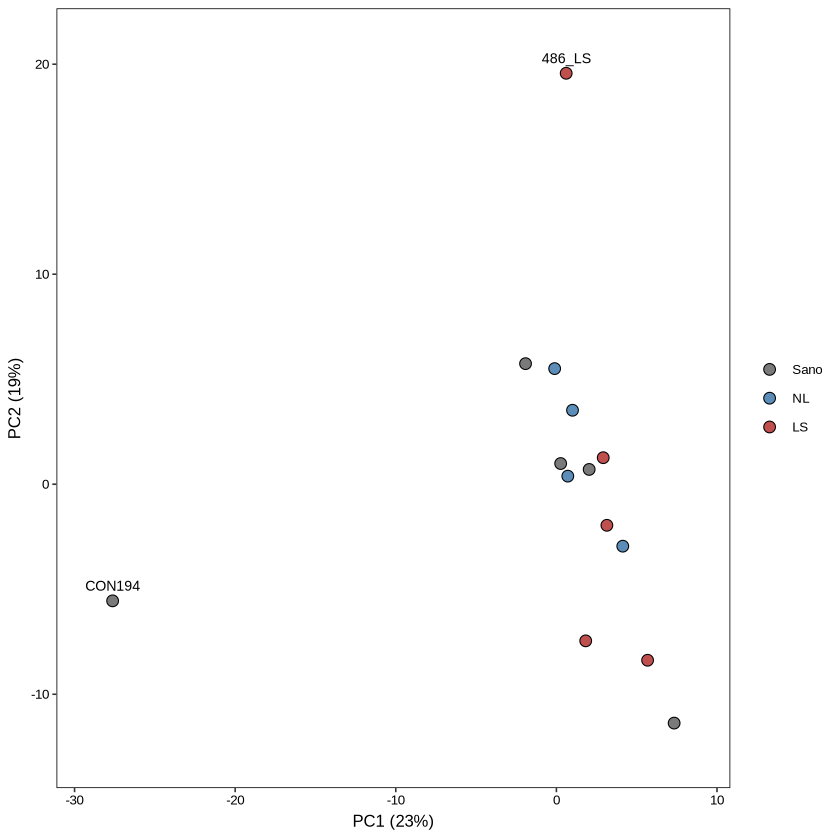

In [4]:
colores <- c(Sano = "#7a7a7a", NL = "#5b8db8", LS = "#c0504d")
tema <- theme_bw(base_size = 10) +
    theme(panel.grid = element_blank(), strip.background = element_blank(),
          panel.border = element_rect(color = "black"),
          axis.text = element_text(color = "black"),
          strip.text = element_text(size = 10))

vsd <- vst(dds, blind = TRUE)
pca <- plotPCA(vsd, intgroup = "condicion", returnData = TRUE)
var_pct <- round(100 * attr(pca, "percentVar"))

p <- ggplot(pca, aes(PC1, PC2, fill = condicion)) +
    geom_point(size = 3, shape = 21, color = "black") +
    geom_text(data = filter(pca, name %in% c("CON194", "486_LS")), aes(label = name),
              vjust = -1, size = 3) +
    scale_fill_manual(values = colores, name = NULL) +
    scale_x_continuous(expand = expansion(mult = 0.1)) +
    scale_y_continuous(expand = expansion(mult = 0.1)) +
    labs(x = paste0("PC1 (", var_pct[1], "%)"), y = paste0("PC2 (", var_pct[2], "%)")) +
    tema
ggsave(file.path(dir_figuras, "pca_pseudobulk_T.png"), p, width = 5, height = 4, dpi = 300)
p

In [5]:
dds <- DESeq(dds)
resultsNames(dds)

estimating size factors



estimating dispersions



gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



fitting model and testing



[1] "Intercept"            "condicion_NL_vs_Sano" "condicion_LS_vs_Sano"

apeglm reduce hacia cero los cambios estimados de genes con pocos conteos, porque esos cambios son muy inestables. La columna `log2FC_shrink` guarda ese valor ajustado.

In [6]:
guardar_de <- function(nivel) {
    res <- results(dds, contrast = c("condicion", nivel, "Sano"), alpha = 0.1)
    shr <- lfcShrink(dds, coef = paste0("condicion_", nivel, "_vs_Sano"),
                     type = "apeglm", quiet = TRUE)
    tabla <- as.data.frame(res) |>
        rownames_to_column("gen") |>
        mutate(log2FC_shrink = shr$log2FoldChange) |>
        arrange(pvalue)
    write.csv(tabla, file.path(dir_tablas, paste0("de_T_", nivel, "_vs_Sano.csv")),
              row.names = FALSE)
    tabla
}

de_nl <- guardar_de("NL")
de_ls <- guardar_de("LS")

cat("NL vs Sano, genes con padj < 0.1:", sum(de_nl$padj < 0.1, na.rm = TRUE), "\n")
cat("LS vs Sano, genes con padj < 0.1:", sum(de_ls$padj < 0.1, na.rm = TRUE), "\n")
head(de_nl, 15)

Warning message in nbinomGLM(x = x, Y = YNZ, size = size, weights = weightsNZ, offset = offsetNZ, :
“the line search routine failed, unable to sufficiently decrease the function value”


NL vs Sano, genes con padj < 0.1: 1 


LS vs Sano, genes con padj < 0.1: 0 


,gen,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,log2FC_shrink
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FXYD2,9.304757,3.1303609,0.7017797,4.460604,8.172912e-06,0.02876865,2.776736e+00
2,ZNF683,11.129335,2.2371008,0.5789571,3.864018,1.115368e-04,0.19630482,1.885885e+00
3,AL133415.1,30.921156,-1.4248581,0.4590976,-3.103606,1.911775e-03,0.99952167,-6.435050e-06
4,STX17-AS1,7.244017,-1.6079346,0.5427552,-2.962541,3.051109e-03,0.99952167,-5.318076e-06
5,JMY,4.533789,-1.8468940,0.6474770,-2.852447,4.338402e-03,0.99952167,-4.822933e-06
6,TNFAIP3,46.917111,-1.3300399,0.4798142,-2.771990,5.571479e-03,0.99952167,-5.618309e-06
7,ITGB2-AS1,8.401436,1.3377565,0.5179012,2.583034,9.793554e-03,0.99952167,5.618553e-06
8,ZFAND2B,7.959404,1.2887112,0.5008792,2.572898,1.008509e-02,0.99952167,5.916729e-06
9,KLRC2,7.910903,1.9159215,0.7618864,2.514708,1.191311e-02,0.99952167,3.561397e-06


Warning message:
“The `fatten` argument of `geom_boxplot()` is deprecated as of ggplot2 4.0.0.
ℹ Please use the `median.linewidth` argument instead.”


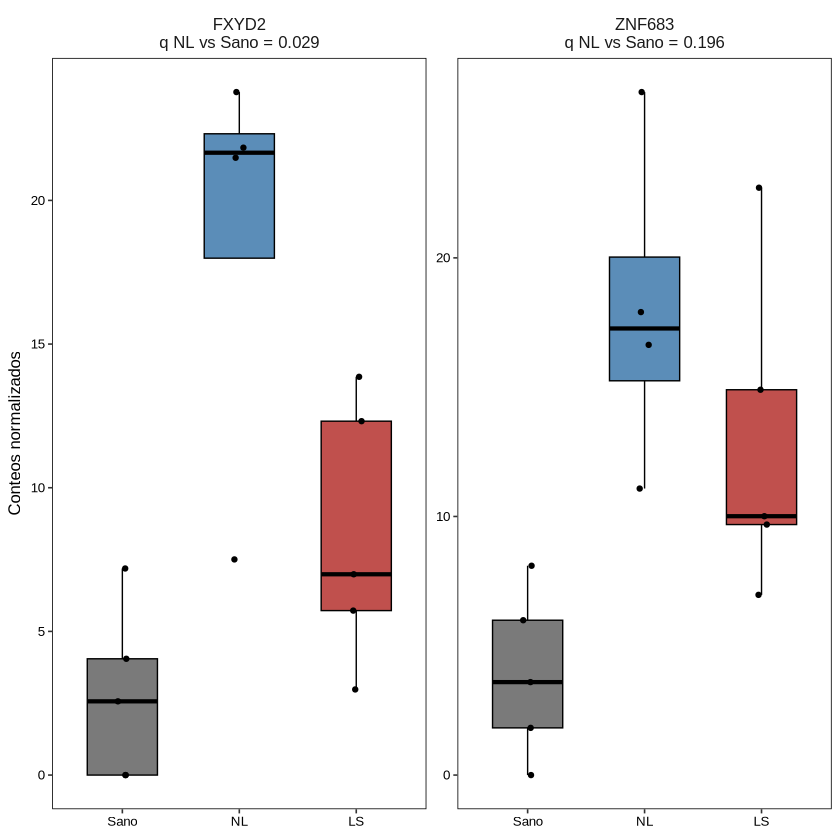

In [7]:
genes_interes <- c("ZNF683", "FXYD2")

q_genes <- de_nl |> filter(gen %in% genes_interes) |> select(gen, padj)
etiquetas <- setNames(sprintf("%s\nq NL vs Sano = %.3f", q_genes$gen, q_genes$padj), q_genes$gen)

nc <- counts(dds, normalized = TRUE)[genes_interes, ] |>
    t() |> as.data.frame() |>
    rownames_to_column("muestra") |>
    left_join(meta |> rownames_to_column("muestra"), by = "muestra") |>
    pivot_longer(all_of(genes_interes), names_to = "gen", values_to = "conteo_norm")

p <- ggplot(nc, aes(condicion, conteo_norm)) +
    geom_boxplot(aes(fill = condicion), width = 0.6, outlier.shape = NA,
                 color = "black", linewidth = 0.4, fatten = 3) +
    geom_jitter(width = 0.05, height = 0, size = 1.2) +
    facet_wrap(~ gen, scales = "free_y", labeller = as_labeller(etiquetas)) +
    scale_fill_manual(values = colores, guide = "none") +
    labs(x = NULL, y = "Conteos normalizados") +
    tema
ggsave(file.path(dir_figuras, "genes_T_NL_vs_Sano.png"), p, width = 6, height = 3.5, dpi = 300)
p

Análisis de sensibilidad: el mismo modelo con el sexo como covariable, porque está desbalanceado entre grupos.

In [8]:
dds_sexo <- dds
design(dds_sexo) <- ~ sexo + condicion
dds_sexo <- DESeq(dds_sexo, quiet = TRUE)

res_sexo <- results(dds_sexo, contrast = c("condicion", "NL", "Sano"))
as.data.frame(res_sexo)[genes_interes, c("log2FoldChange", "pvalue", "padj")]


,log2FoldChange,pvalue,padj
,<dbl>,<dbl>,<dbl>
ZNF683,2.067878,5.432056e-04,0.9563134
FXYD2,3.070658,3.142766e-05,0.1106568


## Heatmap

Cada gen se convierte a z-score, cuántas desviaciones estándar se aleja una muestra del promedio de ese gen. Rojo es por encima del promedio y azul por debajo. El color compara muestras para un mismo gen, no un gen contra otro. Sirve para ver si una firma sube por varios genes juntos o por uno solo.

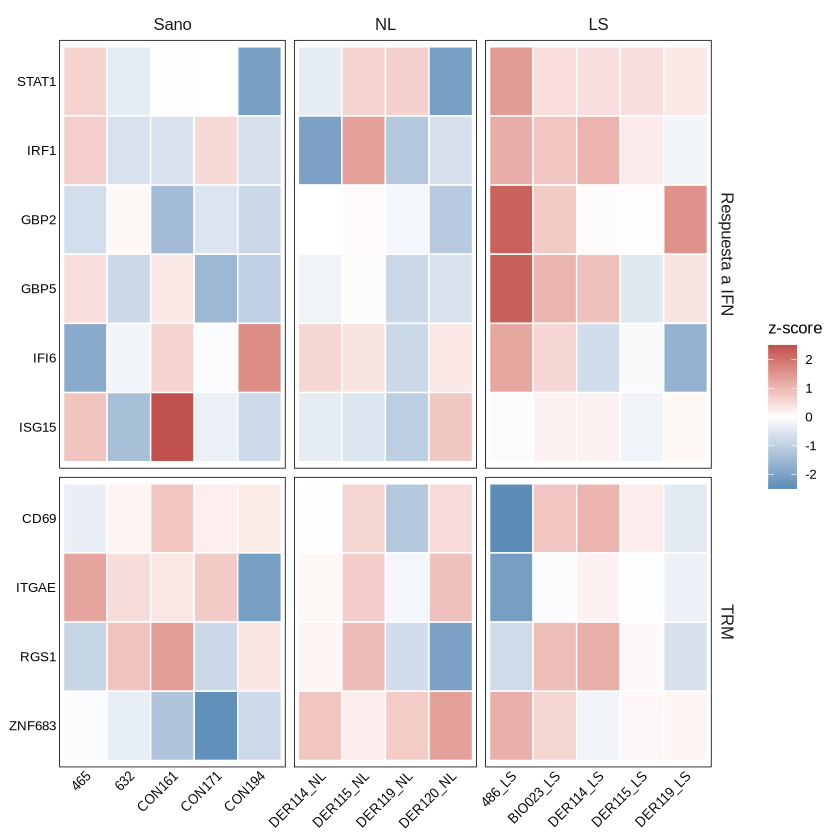

In [9]:
genes_heatmap <- list(
    "Respuesta a IFN" = c("STAT1", "IRF1", "GBP1", "GBP2", "GBP4", "GBP5", "IFI6", "ISG15", "MX1"),
    "TRM" = c("CD69", "ITGAE", "CXCR6", "ITGA1", "PDCD1", "CD101", "CRTAM", "RGS1", "ZNF683")
)

anot_genes <- enframe(genes_heatmap, name = "grupo", value = "gen") |>
    unnest(gen) |>
    filter(gen %in% rownames(vsd))

orden_muestras <- meta |>
    rownames_to_column("muestra") |>
    arrange(condicion, muestra) |>
    pull(muestra)

z <- assay(vsd)[anot_genes$gen, orden_muestras]
z <- t(scale(t(z)))

datos_hm <- as.data.frame(z) |>
    rownames_to_column("gen") |>
    pivot_longer(-gen, names_to = "muestra", values_to = "z") |>
    left_join(anot_genes, by = "gen") |>
    left_join(meta |> rownames_to_column("muestra") |> select(muestra, condicion), by = "muestra") |>
    mutate(gen = factor(gen, levels = rev(anot_genes$gen)),
           muestra = factor(muestra, levels = orden_muestras))

p <- ggplot(datos_hm, aes(muestra, gen, fill = z)) +
    geom_tile(color = "white", linewidth = 0.4) +
    facet_grid(grupo ~ condicion, scales = "free", space = "free") +
    scale_fill_gradient2(low = "#5b8db8", mid = "white", high = "#c0504d",
                         limits = c(-2.5, 2.5), oob = scales::squish) +
    labs(x = NULL, y = NULL, fill = "z-score") +
    tema +
    theme(axis.text.x = element_text(angle = 45, hjust = 1), axis.ticks = element_blank())
ggsave(file.path(dir_figuras, "heatmap_T_IFN_TRM.png"), p, width = 8, height = 6, dpi = 300)
p